# Snapshot ensemble LOQ from equilibrium escape-assay responses

This notebook predicts the concentration precision of one complete ensemble
sensor measurement after the sensor has equilibrated. It combines:

1. the simulated equilibrium occupancy response $\theta(C)$;
2. finite-population fluctuations across the pendula on the electrode;
3. experimentally measured blank and saturated signal distributions;
4. propagation of signal uncertainty into concentration uncertainty.

There is no acquisition-duration or switching-event-counting model. Every
experimental observation is one independently collected sensor measurement
using the established 2 ms molecular-pendulum interrogation protocol.

The LOQ is defined by

$$CV_C(C)=\frac{\sigma_C}{C}=0.10.$$

## 1. Imports and plotting defaults

In [161]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "utils").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from analysis_tools.manuscript_escape_analysis import discover_runs, load_trajectories

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 2. User settings

Enter the mean and SD of the final signal statistic across many independently
collected equilibrated measurements. All four signal values must have the same
units. Do not enter the point-to-point SD inside an individual 2 ms waveform.

The meaning of the resulting LOQ depends on the experimental sampling design:

- repeated measurements of the same electrode estimate within-sensor precision;
- independently fabricated electrodes include between-sensor variability;
- a mixture of the two combines both sources.

In [162]:
# Escape-assay response grid
DATA_ROOT = Path(
    "/Users/rynon/Library/CloudStorage/OneDrive-NorthwesternUniversity/"
    "PhD/Data/Agent-based simulations/"
    "261006_manuscript_final_low_concentration_full_rebinding"
)
CACHE_ROOT = PROJECT_ROOT / ".loq_validation_cache"
REFRESH_CACHE = False

# Experimental endpoint distributions. Replace np.nan with measured values.
BLANK_MEAN_SIGNAL = 0
BLANK_SIGNAL_SD = 3
N_BLANK_MEASUREMENTS = 10

SATURATED_MEAN_SIGNAL = 1000
SATURATED_SIGNAL_SD = 10
N_SATURATED_MEASUREMENTS = 10

# Projected active electrode area corresponding to the measurements above.
# The default is a circular electrode with diameter 20 um.
ELECTRODE_PROJECTED_AREA_MM2 = 0.035
SIMULATED_PATCH_SIDE_NM = 100.0
ACTIVE_AREA_FRACTION = 1.0

# Use this if experimental pendulum density differs from the simulated nominal
# density. For example, 0.5 represents half as many active pendula per area.
EXPERIMENTAL_TO_SIMULATED_DENSITY_RATIO = 1.0

# Number of physical pendula represented by one statistically independent
# occupancy unit. Keep at 1 for independent pendula; values >1 provide a
# sensitivity analysis for spatially correlated occupancy.
PENDULA_PER_INDEPENDENT_UNIT = 1.0

LOQ_CV_THRESHOLD = 0.10
MAX_ACCEPTABLE_CENSORING = 0.01
MIN_EPISODES_PER_LIBRARY = 500

## 3. Validate and normalize the experimental endpoint measurements

In [163]:
def validate_inputs():
    errors = []
    named_values = {
        "BLANK_MEAN_SIGNAL": BLANK_MEAN_SIGNAL,
        "BLANK_SIGNAL_SD": BLANK_SIGNAL_SD,
        "N_BLANK_MEASUREMENTS": N_BLANK_MEASUREMENTS,
        "SATURATED_MEAN_SIGNAL": SATURATED_MEAN_SIGNAL,
        "SATURATED_SIGNAL_SD": SATURATED_SIGNAL_SD,
        "N_SATURATED_MEASUREMENTS": N_SATURATED_MEASUREMENTS,
    }
    for name, value in named_values.items():
        if not np.isfinite(value):
            errors.append(f"Enter a finite value for {name}.")
    if np.isfinite(BLANK_SIGNAL_SD) and BLANK_SIGNAL_SD <= 0:
        errors.append("BLANK_SIGNAL_SD must be positive.")
    if np.isfinite(SATURATED_SIGNAL_SD) and SATURATED_SIGNAL_SD <= 0:
        errors.append("SATURATED_SIGNAL_SD must be positive.")
    for name, value in [
        ("N_BLANK_MEASUREMENTS", N_BLANK_MEASUREMENTS),
        ("N_SATURATED_MEASUREMENTS", N_SATURATED_MEASUREMENTS),
    ]:
        if np.isfinite(value) and (value < 2 or not float(value).is_integer()):
            errors.append(f"{name} must be an integer >= 2.")
    if np.isfinite(BLANK_MEAN_SIGNAL) and np.isfinite(SATURATED_MEAN_SIGNAL):
        if SATURATED_MEAN_SIGNAL == BLANK_MEAN_SIGNAL:
            errors.append("Blank and saturated mean signals cannot be equal.")
    if not np.isfinite(ELECTRODE_PROJECTED_AREA_MM2) or ELECTRODE_PROJECTED_AREA_MM2 <= 0:
        errors.append("ELECTRODE_PROJECTED_AREA_MM2 must be positive.")
    if not 0 < ACTIVE_AREA_FRACTION <= 1:
        errors.append("ACTIVE_AREA_FRACTION must lie in (0, 1].")
    if EXPERIMENTAL_TO_SIMULATED_DENSITY_RATIO <= 0:
        errors.append("EXPERIMENTAL_TO_SIMULATED_DENSITY_RATIO must be positive.")
    if PENDULA_PER_INDEPENDENT_UNIT < 1:
        errors.append("PENDULA_PER_INDEPENDENT_UNIT must be >= 1.")
    if errors:
        raise ValueError("Input validation failed:\n- " + "\n- ".join(errors))


validate_inputs()

SIGNAL_CONTRAST = SATURATED_MEAN_SIGNAL - BLANK_MEAN_SIGNAL
BLANK_SD_NORMALIZED = BLANK_SIGNAL_SD/abs(SIGNAL_CONTRAST)
SATURATED_SD_NORMALIZED = SATURATED_SIGNAL_SD/abs(SIGNAL_CONTRAST)

# Approximate relative uncertainty of an SD estimated from n normal observations.
blank_sd_relative_se = 1/np.sqrt(2*(int(N_BLANK_MEASUREMENTS)-1))
saturated_sd_relative_se = 1/np.sqrt(2*(int(N_SATURATED_MEASUREMENTS)-1))

endpoint_summary = pd.DataFrame({
    "state": ["Blank", "Saturated"],
    "mean_signal": [BLANK_MEAN_SIGNAL, SATURATED_MEAN_SIGNAL],
    "signal_sd": [BLANK_SIGNAL_SD, SATURATED_SIGNAL_SD],
    "normalized_sd": [BLANK_SD_NORMALIZED, SATURATED_SD_NORMALIZED],
    "n_measurements": [int(N_BLANK_MEASUREMENTS), int(N_SATURATED_MEASUREMENTS)],
    "approximate_relative_se_of_sd": [blank_sd_relative_se, saturated_sd_relative_se],
})
display(endpoint_summary)

if min(N_BLANK_MEASUREMENTS, N_SATURATED_MEASUREMENTS) < 20:
    warnings.warn("Fewer than 20 measurements makes the endpoint SD estimate imprecise.")

,state,mean_signal,signal_sd,normalized_sd,n_measurements,approximate_relative_se_of_sd
0,Blank,0,3,0.003,10,0.235702
1,Saturated,1000,10,0.010,10,0.235702


/var/folders/j_/fv2vc19n6vg6gdzlcsqqv6bm0000gn/T/ipykernel_3493/2761646023.py:60: UserWarning: Fewer than 20 measurements makes the endpoint SD estimate imprecise.
  warnings.warn("Fewer than 20 measurements makes the endpoint SD estimate imprecise.")


## 4. Inspect endpoint separation

The normalized endpoint SDs quantify the noise relative to the full blank-to-
saturated response. This plot is diagnostic only; the Gaussian curves are not
used to force a distributional assumption in the LOQ propagation.

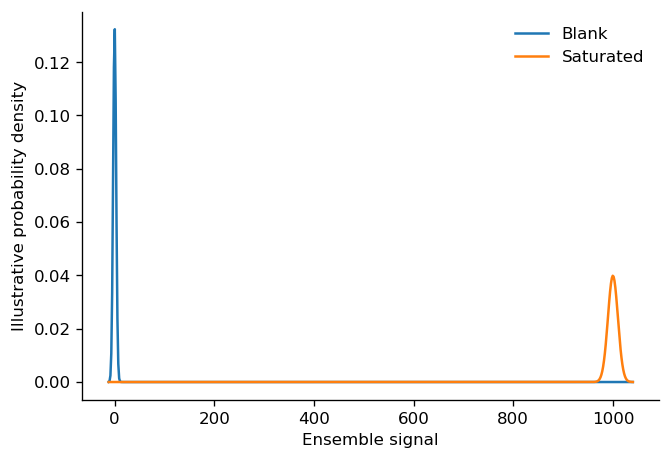

Full-scale contrast-to-blank-SD = 333
Full-scale contrast-to-saturated-SD = 100


In [164]:
x_min = min(BLANK_MEAN_SIGNAL-4*BLANK_SIGNAL_SD,
            SATURATED_MEAN_SIGNAL-4*SATURATED_SIGNAL_SD)
x_max = max(BLANK_MEAN_SIGNAL+4*BLANK_SIGNAL_SD,
            SATURATED_MEAN_SIGNAL+4*SATURATED_SIGNAL_SD)
x = np.linspace(x_min, x_max, 600)

def normal_pdf(x, mean, sd):
    return np.exp(-0.5*((x-mean)/sd)**2)/(sd*np.sqrt(2*np.pi))

fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.plot(x, normal_pdf(x, BLANK_MEAN_SIGNAL, BLANK_SIGNAL_SD), label="Blank")
ax.plot(x, normal_pdf(x, SATURATED_MEAN_SIGNAL, SATURATED_SIGNAL_SD), label="Saturated")
ax.set(xlabel="Ensemble signal", ylabel="Illustrative probability density")
ax.legend(frameon=False)
plt.show()

print(f"Full-scale contrast-to-blank-SD = {abs(SIGNAL_CONTRAST)/BLANK_SIGNAL_SD:.3g}")
print(f"Full-scale contrast-to-saturated-SD = {abs(SIGNAL_CONTRAST)/SATURATED_SIGNAL_SD:.3g}")

## 5. Discover the occupancy-aware escape-assay grid

In [165]:
CACHE_ROOT.mkdir(parents=True, exist_ok=True)
if not DATA_ROOT.exists():
    raise FileNotFoundError(f"Escape-assay folder not found: {DATA_ROOT}")

cache_tag = "261006_final_low_concentration_full_rebinding"
run_index = discover_runs(
    DATA_ROOT,
    cache_path=CACHE_ROOT / f"{cache_tag}_index.csv",
    refresh_cache=REFRESH_CACHE,
).copy()

geometry_labels = {
    "planar_sheet": "Planar",
    "sheet_R100nm": "Curved sheet",
    "sheet_semicircular": "Semicircular sheet",
}
run_index["comparison_label"] = run_index.geometry_name.map(geometry_labels)
if run_index.comparison_label.isna().any():
    unknown = sorted(run_index.loc[run_index.comparison_label.isna(), "geometry_name"].unique())
    raise RuntimeError(f"Unrecognized geometries: {unknown}")

print(f"Discovered {len(run_index):,} run bundles")
display(
    run_index.groupby(["comparison_label", "replicate"])
    .size().rename("occupancy_states").unstack()
)

Discovered 504 run bundles


replicate,1,2,3,4,5,6,7,8
comparison_label,,,,,,,,
Curved sheet,21,21,21,21,21,21,21,21
Planar,21,21,21,21,21,21,21,21
Semicircular sheet,21,21,21,21,21,21,21,21


## 6. Load residence-time summaries and reconstruct $\theta(C)$

Residence time determines the geometry-dependent mean occupancy curve. Episode
second moments are retained for quality control, but they are not used as a
time-averaged event-counting noise term in this snapshot model.

In [166]:
moments_cache = CACHE_ROOT / f"{cache_tag}_episode_moments.csv"
if not moments_cache.exists():
    rows = []
    for number, run in enumerate(run_index.to_dict("records"), start=1):
        trajectories = load_trajectories(run["run_directory"])
        bound = trajectories.total_bound_time_s.to_numpy(float)
        rows.append({
            **run,
            "n_episodes": len(bound),
            "mean_bound_time_s": float(np.mean(bound)),
            "second_bound_moment_s2": float(np.mean(bound**2)),
            "censoring_fraction": float(trajectories.censored.mean()),
            "escape_probability": float(trajectories.escaped.mean()),
        })
        if number % 50 == 0 or number == len(run_index):
            print(f"Read {number:,}/{len(run_index):,} trajectory tables", end="\r")
    print()
    episode_moments = pd.DataFrame(rows)
    episode_moments.to_csv(moments_cache, index=False)
else:
    episode_moments = pd.read_csv(moments_cache)
episode_moments["theta"] = episode_moments.background_occupancy_fraction.astype(float)
episode_moments["KD_classical_M"] = (
    episode_moments.k_off_s.astype(float)/episode_moments.k_on_M_inv_s.astype(float)
)
episode_moments["C_over_KD"] = (
    episode_moments.theta
    / ((1-episode_moments.theta)
       * episode_moments.k_off_s.astype(float)
       * episode_moments.mean_bound_time_s.astype(float))
)
episode_moments["concentration_M"] = (
    episode_moments.C_over_KD*episode_moments.KD_classical_M
)
episode_moments["episode_shape_factor"] = (
    episode_moments.second_bound_moment_s2
    / episode_moments.mean_bound_time_s**2
)

problems = episode_moments.loc[
    (episode_moments.censoring_fraction > MAX_ACCEPTABLE_CENSORING)
    | (episode_moments.n_episodes < MIN_EPISODES_PER_LIBRARY)
]
if len(problems):
    warnings.warn(f"{len(problems)} trajectory libraries fail censoring or sample-size QC.")

display(episode_moments[[
    "comparison_label", "replicate", "theta", "C_over_KD", "n_episodes",
    "mean_bound_time_s", "episode_shape_factor", "censoring_fraction",
]].head())

,comparison_label,replicate,theta,C_over_KD,n_episodes,mean_bound_time_s,episode_shape_factor,censoring_fraction
0,Planar,1,0.000001,3.370259e-07,50000,296.713396,2.013926,0.0
1,Planar,2,0.000001,3.362859e-07,50000,297.366277,2.007708,0.0
2,Planar,3,0.000001,3.381158e-07,50000,295.756924,2.013767,0.0
3,Planar,4,0.000001,3.348835e-07,50000,298.611637,2.007990,0.0
4,Planar,5,0.000001,3.324602e-07,50000,300.788140,1.993049,0.0


## 7. Validate the simulated equilibrium response curves

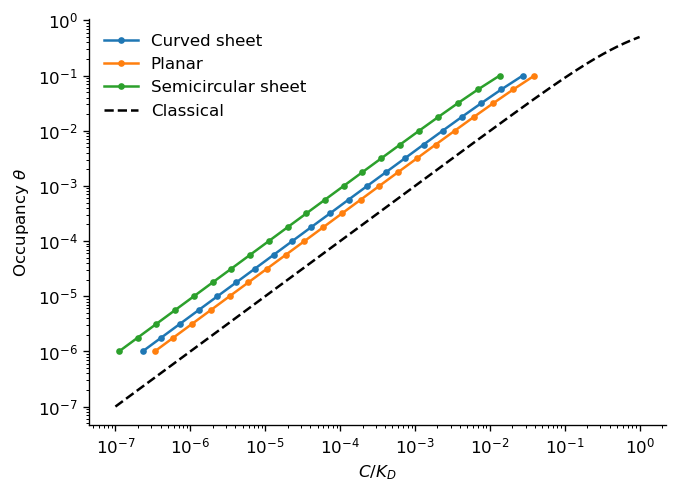

In [167]:
fig, ax = plt.subplots(figsize=(6.2, 4.4))
for label, group in episode_moments.groupby("comparison_label"):
    curve = group.groupby("theta", as_index=False).agg(
        C_over_KD=("C_over_KD", "mean"),
        C_sem=("C_over_KD", "sem"),
    ).sort_values("theta")
    ax.plot(curve.C_over_KD, curve.theta, marker="o", ms=3, label=label)
classical_x = np.logspace(-7, 0, 400)
ax.plot(classical_x, classical_x/(1+classical_x), "--", color="black", label="Classical")
ax.set(xscale="log", yscale="log", xlabel=r"$C/K_D$", ylabel=r"Occupancy $\theta$")
ax.legend(frameon=False)
plt.show()

## 8. Scale receptor number to the experimental electrode

Receptor number is used only for finite-population occupancy variance. The
measured endpoint SDs already describe the full experimental electrode and are
therefore not rescaled by area.

In [168]:
electrode_area_m2 = ELECTRODE_PROJECTED_AREA_MM2*1e-6
patch_area_m2 = (SIMULATED_PATCH_SIDE_NM*1e-9)**2
projected_patch_copies = ACTIVE_AREA_FRACTION*electrode_area_m2/patch_area_m2

episode_moments["physical_pendula"] = (
    episode_moments.n_receptors.astype(float)
    * projected_patch_copies
    * EXPERIMENTAL_TO_SIMULATED_DENSITY_RATIO
)
episode_moments["effective_independent_pendula"] = (
    episode_moments.physical_pendula/PENDULA_PER_INDEPENDENT_UNIT
)

area_summary = episode_moments.groupby("comparison_label").agg(
    simulated_receptors_per_patch=("n_receptors", "mean"),
    physical_pendula=("physical_pendula", "mean"),
    effective_independent_pendula=("effective_independent_pendula", "mean"),
).reset_index()
area_summary.insert(1, "electrode_area_mm2", ELECTRODE_PROJECTED_AREA_MM2)
area_summary.insert(2, "projected_patch_copies", projected_patch_copies)
display(area_summary)

,comparison_label,electrode_area_mm2,projected_patch_copies,simulated_receptors_per_patch,physical_pendula,effective_independent_pendula
0,Curved sheet,0.035,3500000.0,640.0,2.240000e+09,2.240000e+09
1,Planar,0.035,3500000.0,500.0,1.750000e+09,1.750000e+09
2,Semicircular sheet,0.035,3500000.0,1000.0,3.500000e+09,3.500000e+09


## 9. Snapshot variance model

For normalized signal $y=(S-S_0)/(S_{\mathrm{sat}}-S_0)$, assume $E[y]=\theta$.
The finite-population molecular variance is

$$\sigma_{\mathrm{mol}}^2=\frac{\theta(1-\theta)}{N_{\mathrm{eff}}}.$$

Measured endpoint variances are mixed across occupancy:

$$\sigma_{\mathrm{endpoint}}^2(\theta)
=(1-\theta)\sigma_0^2+\theta\sigma_{\mathrm{sat}}^2.$$

This interpolation is explicit and exactly recovers the two measured endpoints.
It can later be replaced with measured intermediate-occupancy variance.

In [169]:
def monotone_calibration(group):
    curve = group.sort_values("theta").copy()
    valid = (
        np.isfinite(curve.C_over_KD) & (curve.C_over_KD > 0)
        & (curve.theta > 0) & (curve.theta < 1)
    )
    curve = curve.loc[valid].copy()
    log_c = np.maximum.accumulate(np.log(curve.C_over_KD.to_numpy(float)))
    for i in range(1, len(log_c)):
        if log_c[i] <= log_c[i-1]:
            log_c[i] = log_c[i-1] + 1e-9
    curve["log_C_monotone"] = log_c
    return curve


def first_log_crossing(x, y, threshold):
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    order = np.argsort(x)
    x, y = x[order], y[order]
    valid = np.isfinite(x) & np.isfinite(y) & (x > 0) & (y > 0)
    x, y = x[valid], y[valid]
    reached = np.flatnonzero(y <= threshold)
    if not len(reached):
        return np.nan
    j = int(reached[0])
    if j == 0:
        return x[0]
    lx = np.log(x[j-1:j+1])
    ly = np.log(y[j-1:j+1])
    if ly[1] == ly[0]:
        return x[j]
    return float(np.exp(
        lx[0] + (np.log(threshold)-ly[0])*(lx[1]-lx[0])/(ly[1]-ly[0])
    ))


precision_rows = []
loq_rows = []
for (label, replicate), raw_group in episode_moments.groupby(
    ["comparison_label", "replicate"]
):
    group = monotone_calibration(raw_group)
    theta = group.theta.to_numpy(float)
    log_c = group.log_C_monotone.to_numpy(float)
    beta = np.gradient(np.log(theta), log_c)
    beta = np.where(beta > 0, beta, np.nan)
    n_eff = group.effective_independent_pendula.to_numpy(float)

    molecular_variance = theta*(1-theta)/n_eff
    endpoint_variance = (
        (1-theta)*BLANK_SD_NORMALIZED**2
        + theta*SATURATED_SD_NORMALIZED**2
    )
    total_variance = molecular_variance + endpoint_variance
    denominator = theta*beta

    cv_molecular = np.sqrt(molecular_variance)/denominator
    cv_endpoint = np.sqrt(endpoint_variance)/denominator
    cv_total = np.sqrt(total_variance)/denominator

    for i in range(len(group)):
        precision_rows.append({
            "comparison_label": label,
            "replicate": replicate,
            "theta": theta[i],
            "C_over_KD": float(group.C_over_KD.iloc[i]),
            "concentration_M": float(group.concentration_M.iloc[i]),
            "beta": beta[i],
            "physical_pendula": float(group.physical_pendula.iloc[i]),
            "effective_independent_pendula": n_eff[i],
            "molecular_variance": molecular_variance[i],
            "endpoint_variance": endpoint_variance[i],
            "total_variance": total_variance[i],
            "CV_C_molecular": cv_molecular[i],
            "CV_C_endpoint": cv_endpoint[i],
            "CV_C_total": cv_total[i],
        })

    c_ratio = group.C_over_KD.to_numpy(float)
    loq_rows.append({
        "comparison_label": label,
        "replicate": replicate,
        "LOQ_over_KD": first_log_crossing(c_ratio, cv_total, LOQ_CV_THRESHOLD),
        "molecular_only_LOQ_over_KD": first_log_crossing(
            c_ratio, cv_molecular, LOQ_CV_THRESHOLD
        ),
        "endpoint_only_LOQ_over_KD": first_log_crossing(
            c_ratio, cv_endpoint, LOQ_CV_THRESHOLD
        ),
    })

precision_grid = pd.DataFrame(precision_rows)
loq_results = pd.DataFrame(loq_rows)
display(precision_grid.head())

,comparison_label,replicate,theta,C_over_KD,concentration_M,beta,physical_pendula,effective_independent_pendula,molecular_variance,endpoint_variance,total_variance,CV_C_molecular,CV_C_endpoint,CV_C_total
0,Curved sheet,1,0.000001,2.329761e-07,2.329761e-16,0.999999,2.240000e+09,2.240000e+09,4.464281e-16,0.000009,0.000009,0.021129,3000.019223,3000.019223
1,Curved sheet,1,0.000002,4.142969e-07,4.142969e-16,0.999998,2.240000e+09,2.240000e+09,7.938733e-16,0.000009,0.000009,0.015844,1687.042311,1687.042311
2,Curved sheet,1,0.000003,7.367367e-07,7.367367e-16,0.999997,2.240000e+09,2.240000e+09,1.411727e-15,0.000009,0.000009,0.011882,948.701633,948.701633
3,Curved sheet,1,0.000006,1.310127e-06,1.310127e-15,0.999294,2.240000e+09,2.240000e+09,2.510438e-15,0.000009,0.000009,0.008916,533.876059,533.876059
4,Curved sheet,1,0.000010,2.331665e-06,2.331665e-15,0.999289,2.240000e+09,2.240000e+09,4.464241e-15,0.000009,0.000009,0.006686,300.228604,300.228604


## 10. Validate the noise budget

This determines whether the predicted LOQ is controlled by finite molecular
occupancy or by the experimentally measured endpoint distributions. With
millions of pendula, endpoint variance is expected to dominate unless the
blank-to-saturated contrast is exceptionally precise.

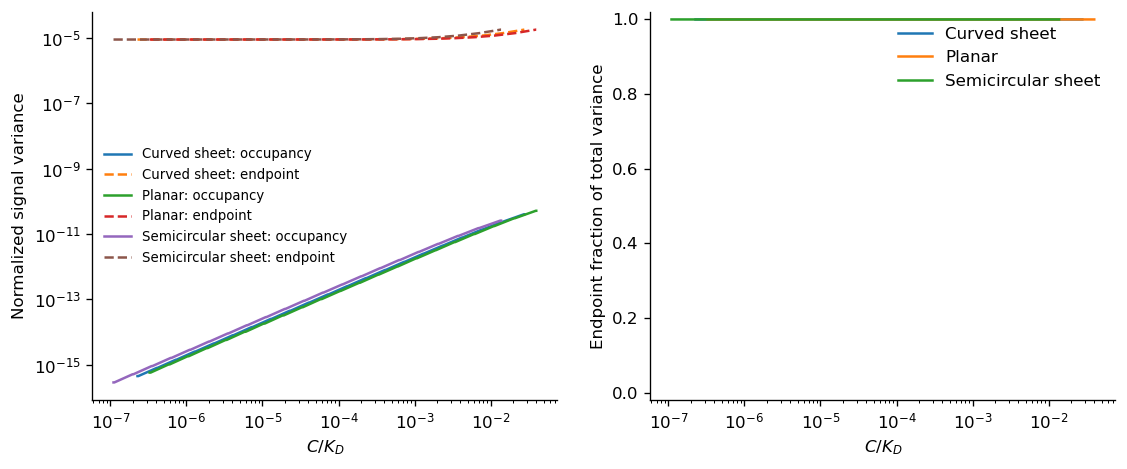

In [170]:
variance_summary = precision_grid.groupby(
    ["comparison_label", "C_over_KD"], as_index=False
).agg(
    molecular_variance=("molecular_variance", "mean"),
    endpoint_variance=("endpoint_variance", "mean"),
    total_variance=("total_variance", "mean"),
)
variance_summary["endpoint_fraction"] = (
    variance_summary.endpoint_variance/variance_summary.total_variance
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for label, group in variance_summary.groupby("comparison_label"):
    axes[0].plot(group.C_over_KD, group.molecular_variance, label=f"{label}: occupancy")
    axes[0].plot(group.C_over_KD, group.endpoint_variance, linestyle="--",
                 label=f"{label}: endpoint")
    axes[1].plot(group.C_over_KD, group.endpoint_fraction, label=label)
axes[0].set(xscale="log", yscale="log", xlabel=r"$C/K_D$", ylabel="Normalized signal variance")
axes[1].set(xscale="log", ylim=(-0.02, 1.02), xlabel=r"$C/K_D$",
            ylabel="Endpoint fraction of total variance")
axes[0].legend(frameon=False, fontsize=8)
axes[1].legend(frameon=False)
plt.show()

## 11. Validate concentration sensitivity

The local logarithmic slope

$$\beta=\frac{d\ln\theta}{d\ln C}$$

determines how signal error maps into concentration error. A left-shifted curve
does not guarantee improved quantification if it becomes locally flat.

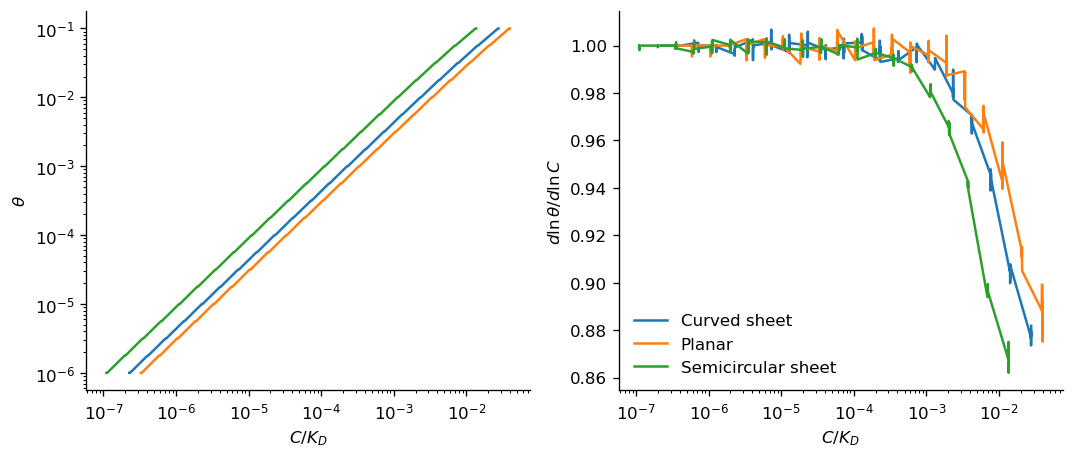

In [171]:
slope_summary = precision_grid.groupby(
    ["comparison_label", "C_over_KD"], as_index=False
).agg(theta=("theta", "mean"), beta=("beta", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.1))
for label, group in slope_summary.groupby("comparison_label"):
    axes[0].plot(group.C_over_KD, group.theta, label=label)
    axes[1].plot(group.C_over_KD, group.beta, label=label)
axes[0].set(xscale="log", yscale="log", xlabel=r"$C/K_D$", ylabel=r"$\theta$")
axes[1].set(xscale="log", xlabel=r"$C/K_D$", ylabel=r"$d\ln\theta/d\ln C$")
axes[1].legend(frameon=False)
plt.show()

## 12. Snapshot concentration-precision curves

Solid curves include both finite-population occupancy variance and measured
endpoint variance. Dotted and dashed curves isolate the two contributions.

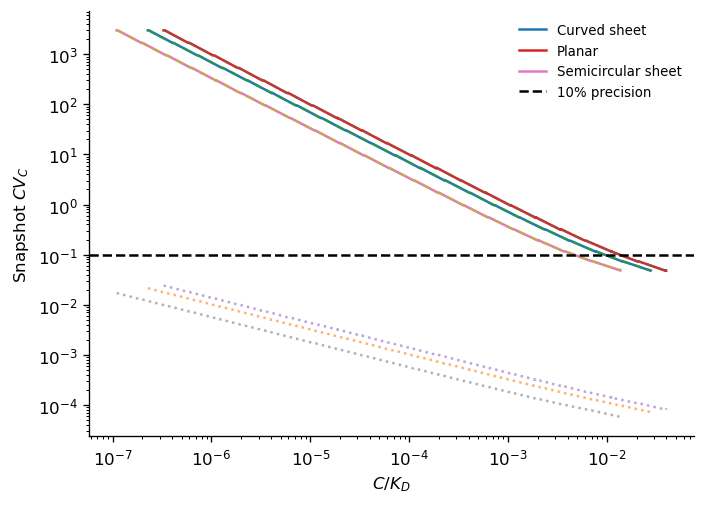

In [172]:
mean_precision = precision_grid.groupby(
    ["comparison_label", "C_over_KD"], as_index=False
).agg(
    CV_C_total=("CV_C_total", "mean"),
    CV_C_molecular=("CV_C_molecular", "mean"),
    CV_C_endpoint=("CV_C_endpoint", "mean"),
)

fig, ax = plt.subplots(figsize=(6.5, 4.6))
for label, group in mean_precision.groupby("comparison_label"):
    ax.plot(group.C_over_KD, group.CV_C_total, label=label)
    ax.plot(group.C_over_KD, group.CV_C_molecular, linestyle=":", alpha=0.6)
    ax.plot(group.C_over_KD, group.CV_C_endpoint, linestyle="--", alpha=0.6)
ax.axhline(LOQ_CV_THRESHOLD, color="black", linestyle="--", label="10% precision")
ax.set(xscale="log", yscale="log", xlabel=r"$C/K_D$", ylabel=r"Snapshot $CV_C$")
ax.legend(frameon=False, fontsize=8)
plt.show()

## 13. Extract the snapshot ensemble LOQ

,comparison_label,LOQ_over_KD_mean,LOQ_over_KD_sem,resolved_replicates,molecular_only_LOQ,endpoint_only_LOQ
0,Curved sheet,0.009396,0.000024,8,2.304086e-07,0.009396
1,Planar,0.013516,0.000040,8,3.344311e-07,0.013516
2,Semicircular sheet,0.004611,0.000015,8,1.116921e-07,0.004611


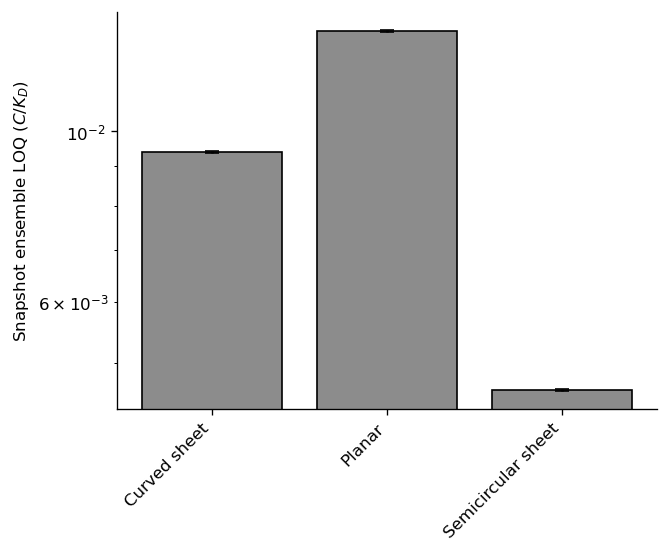

In [173]:
loq_summary = loq_results.groupby("comparison_label").agg(
    LOQ_over_KD_mean=("LOQ_over_KD", "mean"),
    LOQ_over_KD_sem=("LOQ_over_KD", "sem"),
    resolved_replicates=("LOQ_over_KD", "count"),
    molecular_only_LOQ=("molecular_only_LOQ_over_KD", "mean"),
    endpoint_only_LOQ=("endpoint_only_LOQ_over_KD", "mean"),
).reset_index()
display(loq_summary)

if loq_results.LOQ_over_KD.isna().any():
    unresolved = loq_results.loc[loq_results.LOQ_over_KD.isna()]
    warnings.warn(
        f"{len(unresolved)} LOQ crossings are unresolved inside the simulated "
        "concentration range and remain NaN rather than being extrapolated."
    )

fig, ax = plt.subplots(figsize=(5.8, 4.3))
x = np.arange(len(loq_summary))
ax.bar(
    x, loq_summary.LOQ_over_KD_mean,
    yerr=loq_summary.LOQ_over_KD_sem,
    capsize=4, color="0.55", edgecolor="black",
)
ax.set(
    xticks=x, xticklabels=loq_summary.comparison_label,
    yscale="log", ylabel=r"Snapshot ensemble LOQ ($C/K_D$)",
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.show()

## 14. Sensitivity to experimental signal precision

A multiplier below one represents either lower endpoint SD or proportionally
greater blank-to-saturated contrast. Molecular occupancy variance is left
unchanged.

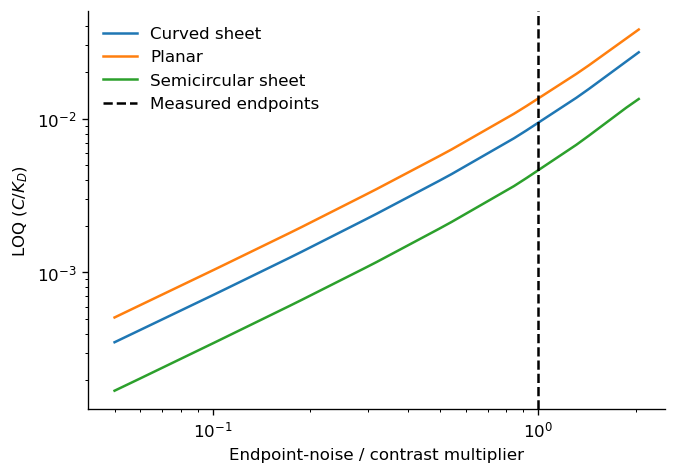

In [174]:
noise_multipliers = np.geomspace(0.05, 10.0, 61)
sensitivity_rows = []

for (label, replicate), group in precision_grid.groupby(["comparison_label", "replicate"]):
    c = group.C_over_KD.to_numpy(float)
    denominator = group.theta.to_numpy(float)*group.beta.to_numpy(float)
    for multiplier in noise_multipliers:
        variance = (
            group.molecular_variance.to_numpy(float)
            + multiplier**2*group.endpoint_variance.to_numpy(float)
        )
        cv = np.sqrt(variance)/denominator
        sensitivity_rows.append({
            "comparison_label": label,
            "replicate": replicate,
            "noise_multiplier": multiplier,
            "LOQ_over_KD": first_log_crossing(c, cv, LOQ_CV_THRESHOLD),
        })

sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity_mean = sensitivity.groupby(
    ["comparison_label", "noise_multiplier"], as_index=False
).LOQ_over_KD.mean()

fig, ax = plt.subplots(figsize=(6.2, 4.3))
for label, group in sensitivity_mean.groupby("comparison_label"):
    ax.plot(group.noise_multiplier, group.LOQ_over_KD, label=label)
ax.axvline(1, color="black", linestyle="--", label="Measured endpoints")
ax.set(
    xscale="log", yscale="log",
    xlabel="Endpoint-noise / contrast multiplier",
    ylabel=r"LOQ ($C/K_D$)",
)
ax.legend(frameon=False)
plt.show()

## 15. Sensitivity to effective independent pendulum number

This tests the independent-pendulum assumption without altering the measured
endpoint noise. If endpoint noise dominates, even large occupancy correlations
will have little influence on the predicted LOQ.

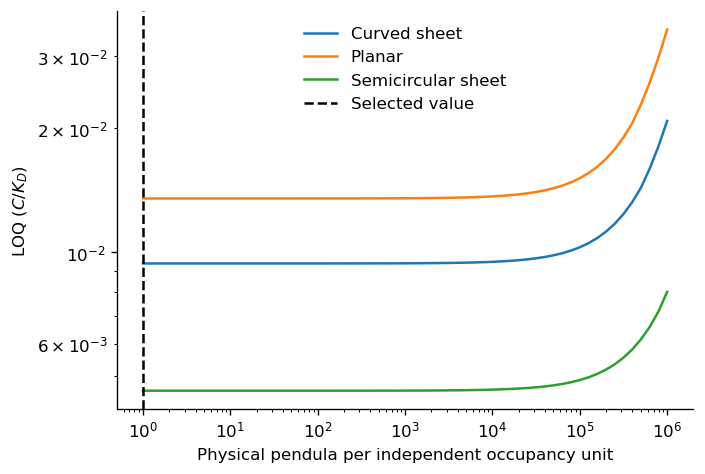

In [175]:
correlation_factors = np.geomspace(1, 1e6, 61)
correlation_rows = []

for (label, replicate), group in precision_grid.groupby(["comparison_label", "replicate"]):
    c = group.C_over_KD.to_numpy(float)
    theta = group.theta.to_numpy(float)
    physical_n = group.physical_pendula.to_numpy(float)
    endpoint_var = group.endpoint_variance.to_numpy(float)
    denominator = theta*group.beta.to_numpy(float)
    for factor in correlation_factors:
        molecular_var = theta*(1-theta)/(physical_n/factor)
        cv = np.sqrt(molecular_var + endpoint_var)/denominator
        correlation_rows.append({
            "comparison_label": label,
            "replicate": replicate,
            "pendula_per_independent_unit": factor,
            "LOQ_over_KD": first_log_crossing(c, cv, LOQ_CV_THRESHOLD),
        })

correlation_sensitivity = pd.DataFrame(correlation_rows)
correlation_mean = correlation_sensitivity.groupby(
    ["comparison_label", "pendula_per_independent_unit"], as_index=False
).LOQ_over_KD.mean()

fig, ax = plt.subplots(figsize=(6.2, 4.3))
for label, group in correlation_mean.groupby("comparison_label"):
    ax.plot(group.pendula_per_independent_unit, group.LOQ_over_KD, label=label)
ax.axvline(PENDULA_PER_INDEPENDENT_UNIT, color="black", linestyle="--",
           label="Selected value")
ax.set(
    xscale="log", yscale="log",
    xlabel="Physical pendula per independent occupancy unit",
    ylabel=r"LOQ ($C/K_D$)",
)
ax.legend(frameon=False)
plt.show()

## Interpretation checklist

Before reporting the result:

1. Confirm every experimental observation is a complete, identically processed
   sensor measurement and that the observations used for each SD are independent.
2. State explicitly whether the SD is within-sensor, between-sensor, or combined.
3. Confirm the saturated condition is sufficiently close to $\theta=1$ to serve
   as the bound endpoint.
4. Verify that electrode area and pendulum-density scaling describe the measured
   sensors.
5. Inspect whether endpoint variance or finite-population occupancy dominates.
6. Treat variance interpolation between blank and saturation as an assumption;
   intermediate-concentration measurements can validate or replace it.
7. Do not report an LOQ crossing outside the simulated concentration range.

In this formulation, residence and rebinding shift the simulated mean occupancy
and its concentration sensitivity. Experimental endpoint distributions determine
whether that shift is resolvable by one equilibrium ensemble measurement.